In [20]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnext50_32x4d
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import time

In [21]:
class ResNeXtBottleneck(nn.Module):
    expansion: int = 4 #коефіцієнт розширення кількості каналів на виході з блоку відносно base_channel_coeff
    ##in_channels - фактична кількість каналів, яка приходить на вхід даного блока
    ##base_channel_coefficient - абстрактний коефіцієнт поточного блоку, який використовується для обчислення інших параметрів (з літератури оригінальної)
    ##cardinality - кількість паралельних груп в груповій згортці
    ##first_step_group_width - ширина(кількість каналів) однієї групи на першому етапі
    ##current_one_group_channels - ширина(кількість каналів) однієї групи на поточному етапі
    ##total_groups_channels - сумарна ширина(кількість каналів) для всіх груп

    def __init__(self, in_channels: int, base_channel_coefficient: int, stride: int = 1, cardinality: int = 32, first_step_group_width: int = 4):
        super(ResNeXtBottleneck, self).__init__()

        current_one_group_channels = int(base_channel_coefficient * (first_step_group_width / 64)) #поточна кількість каналів в одній групі
        total_groups_channels = cardinality * current_one_group_channels ##сумарна кількість каналів в усіх групах - на першому кроці 128

        self.conv1 = nn.Conv2d(in_channels, total_groups_channels, kernel_size=1, bias=False) #проектує вхідний тензор у сумарну кількість проміжних каналів (total_group_channels)
        self.bn1 = nn.BatchNorm2d(total_groups_channels)

        self.conv2 = nn.Conv2d(
            total_groups_channels, total_groups_channels, kernel_size=3, stride=stride,
            padding=1, groups=cardinality, bias=False
        ) ##застосування групової згортки
        self.bn2 = nn.BatchNorm2d(total_groups_channels)

        self.conv3 = nn.Conv2d(total_groups_channels, base_channel_coefficient * self.expansion, kernel_size=1, bias=False) ##розширує кількість каналів дл фінального розміру
        self.bn3 = nn.BatchNorm2d(base_channel_coefficient * self.expansion)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != base_channel_coefficient * self.expansion: ##підганяє розмірність карти ознак та кількість каналів
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, base_channel_coefficient * self.expansion, kernel_size=1, stride=stride, bias=False), ##проективне перетворення, якщо розмірність карти ознак або кількість каналів не збігаються
                nn.BatchNorm2d(base_channel_coefficient * self.expansion)
            )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)))
        out = F.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        out += self.shortcut(x)
        return F.relu(out)

In [22]:
class ResNeXt50FromScratch(nn.Module):
    def __init__(self, feature_dim: int = 32, cardinality: int = 32, first_step_group_width: int = 4):
        super(ResNeXt50FromScratch, self).__init__()
        self.in_channels = 64
        self.cardinality = cardinality
        self.first_step_group_width = first_step_group_width

        self.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False) #адаптація ResNext-50 під датасет Fashion-Mnist
        self.bn1 = nn.BatchNorm2d(64)

        self.layer1 = self._make_layer(base_channel_coefficient=64, blocks=3, stride=1)
        self.layer2 = self._make_layer(base_channel_coefficient=128, blocks=4, stride=2)
        self.layer3 = self._make_layer(base_channel_coefficient=256, blocks=6, stride=2)
        self.layer4 = self._make_layer(base_channel_coefficient=512, blocks=3, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        self.fc = nn.Sequential(
            nn.Linear(512 * ResNeXtBottleneck.expansion, 128), #(2048,128)
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, feature_dim),
            nn.BatchNorm1d(feature_dim),
            nn.ReLU()
        )

    def _make_layer(self, base_channel_coefficient: int, blocks: int, stride: int) -> nn.Sequential:
        strides = [stride] + [1] * (blocks - 1) #список страйдів для згорток
        layers = []
        for s in strides:
            layers.append(
                ResNeXtBottleneck(
                    self.in_channels, base_channel_coefficient, stride=s,
                    cardinality=self.cardinality, first_step_group_width=self.first_step_group_width
                )
            )
            self.in_channels = base_channel_coefficient * ResNeXtBottleneck.expansion
        return nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = self.avgpool(out)
        out = torch.flatten(out, 1)
        out = self.fc(out)
        return out

In [23]:
class ResNeXt50Classifier(nn.Module):
    def __init__(self, num_classes: int = 10, cardinality: int = 32, first_step_group_width: int = 4):
        super(ResNeXt50Classifier, self).__init__()
        self.backbone = ResNeXt50FromScratch(feature_dim=128, cardinality=cardinality, first_step_group_width=first_step_group_width)

        self.backbone.fc = nn.Sequential(
            nn.Linear(512 * ResNeXtBottleneck.expansion, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.backbone(x)

In [24]:
def get_feature_extractor(model_type: str = 'custom', feature_dim: int = 32) -> nn.Module:
    if model_type == 'custom':
        print("Ініціалізація ВЛАСНОЇ архітектури ResNeXt-50...")
        return ResNeXt50FromScratch(feature_dim=feature_dim)
    elif model_type == 'torchvision':
        print("Ініціалізація ГОТОВОЇ архітектури ResNeXt-50 з torchvision")
        base_model = resnext50_32x4d(weights=None)
        base_model.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
        base_model.maxpool = nn.Identity()
        in_features = base_model.fc.in_features
        base_model.fc = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, feature_dim),
            nn.BatchNorm1d(feature_dim),
            nn.ReLU()
        )
        return base_model
    else:
        raise ValueError(f"Невідомий тип моделі: '{model_type}'. Очікується 'custom' або 'torchvision'.")


In [25]:
def get_classifier(model_type: str = 'custom', num_classes: int = 10) -> nn.Module:
    if model_type == 'custom':
        print("Ініціалізація ВЛАСНОГО класифікатора ResNeXt-50...")
        return ResNeXt50Classifier(num_classes=num_classes)
    elif model_type == 'torchvision':
        print("Ініціалізація ГОТОВОГО класифікатора ResNeXt-50 з torchvision...")
        base_model = resnext50_32x4d(weights=None)
        base_model.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
        base_model.maxpool = nn.Identity()
        in_features = base_model.fc.in_features
        base_model.fc = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
        return base_model
    else:
        raise ValueError(f"Невідомий тип моделі: '{model_type}'. Очікується 'custom' або 'torchvision'.")

In [26]:
class SiameseNet(nn.Module):
    def __init__(self, feature_extractor: nn.Module, feature_dim: int = 32):
        super(SiameseNet, self).__init__()
        self.feature_extractor = feature_extractor
        self.similarity_head = nn.Sequential(
            nn.Linear(feature_dim * 2, 16),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.Linear(16, 4),
            nn.BatchNorm1d(4),
            nn.ReLU(),
            nn.Linear(4, 1),
            nn.Sigmoid()
        )

    def forward(self, first_image: torch.Tensor, second_image: torch.Tensor) -> torch.Tensor:
        first_image_features = self.feature_extractor(first_image)
        second_image_features = self.feature_extractor(second_image)
        combined_features = torch.cat((first_image_features, second_image_features), dim=1)
        similarity = self.similarity_head(combined_features)
        return similarity

In [27]:
class SiameseFashionMNIST(Dataset):
    def __init__(self, mnist_dataset, num_pairs: int = None, seed: int = 42):
        self.dataset = mnist_dataset
        self.labels = np.array(mnist_dataset.targets)
        self.num_pairs = num_pairs if num_pairs is not None else len(mnist_dataset)
        self.rng = np.random.RandomState(seed)
        self.group_indices = [np.where(self.labels == i)[0] for i in range(10)]

        self.pairs, self.targets = self._generate_pairs()

    def _generate_pairs(self):
        pairs = []
        targets = []

        for i in range(self.num_pairs):
            first_idx = i % len(self.dataset)
            first_label = self.labels[first_idx]

            match_group = self.rng.choice([True, False])
            if match_group:
                second_idx = self.rng.choice(self.group_indices[first_label])
                target = 1.0
            else:
                diff_label = self.rng.choice([l for l in range(10) if l != first_label])
                second_idx = self.rng.choice(self.group_indices[diff_label])
                target = 0.0

            pairs.append((first_idx, second_idx))
            targets.append(target)

        return pairs, np.array(targets, dtype=np.float32)

    def __getitem__(self, index: int):
        idx1, idx2 = self.pairs[index]

        first_image, _ = self.dataset[idx1]
        second_image, _ = self.dataset[idx2]
        target = torch.tensor([self.targets[index]], dtype=torch.float32)

        return first_image, second_image, target

    def __len__(self) -> int:
        return self.num_pairs

In [28]:
def show_model_predictions(siamese_model: nn.Module, test_dataset: Dataset, device: torch.device, examples_amount: int = 6):
    siamese_model.eval()
    siamese_dataset = SiameseFashionMNIST(test_dataset)
    loader = DataLoader(siamese_dataset, batch_size=examples_amount, shuffle=True)

    first_image, second_image, target = next(iter(loader))
    with torch.no_grad():
        pred_sim = siamese_model(first_image.to(device), second_image.to(device)).cpu().numpy()

    fig, axs = plt.subplots(2, examples_amount, figsize=(14, 5))
    for idx in range(examples_amount):
        axs[0, idx].imshow(first_image[idx][0].numpy(), cmap='viridis')
        axs[0, idx].set_title(f"Image A\nActual: {int(target[idx].item() * 100)}%")
        axs[0, idx].axis('off')

        axs[1, idx].imshow(second_image[idx][0].numpy(), cmap='viridis')
        axs[1, idx].set_title(f"Image B\nPredicted: {int(pred_sim[idx][0] * 100)}%")
        axs[1, idx].axis('off')

    plt.tight_layout()
    plt.savefig('siamese_predictions_result.png')
    plt.show()

In [47]:
def visualize_tsne(feature_extractor: nn.Module, test_loader: DataLoader, device: torch.device):
    feature_extractor.eval()
    all_features = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            features = feature_extractor(images)
            all_features.append(features.cpu().numpy())
            all_labels.append(labels.numpy())

    features_arr = np.concatenate(all_features, axis=0)
    labels_arr = np.concatenate(all_labels, axis=0)

    print("Обчислення t-SNE проекції на 2D площину...", flush=True)
    tsne = TSNE(n_components=2, init='pca', random_state=42, n_iter=500, verbose=1)
    tsne_results = tsne.fit_transform(features_arr)

    categories = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
                  'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
    colors = plt.cm.rainbow(np.linspace(0, 1, 10))

    plt.figure(figsize=(10, 10))
    for idx, (color, label) in enumerate(zip(colors, categories)):
        mask = labels_arr == idx
        plt.scatter(tsne_results[mask, 0], tsne_results[mask, 1],
                    c=[color], label=label, alpha=0.7, s=15)

    plt.xlabel('Dimension 1')
    plt.ylabel('Dimension 2')
    plt.title('t-SNE on Fashion-MNIST Testing Samples (ResNeXt-50 Features)')
    plt.legend(loc='best')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.savefig('clothes_tsne_resnext50.png')
    plt.show()

In [49]:
def evaluate_siamese_metrics(siamese_model: nn.Module, test_dataset: Dataset, device: torch.device, threshold: float = 0.5):
    siamese_model.eval()
    siamese_test_ds = SiameseFashionMNIST(test_dataset)
    test_loader = DataLoader(siamese_test_ds, batch_size=256, shuffle=False)

    all_targets = []
    all_preds_prob = []

    with torch.no_grad():
        for first_image, second_image, target in test_loader:
            first_image, second_image = first_image.to(device), second_image.to(device)
            preds = siamese_model(first_image, second_image).cpu().squeeze().numpy()

            all_preds_prob.extend(preds)
            all_targets.extend(target.numpy().squeeze())

    all_targets = np.array(all_targets)
    all_preds_prob = np.array(all_preds_prob)
    all_preds_binary = (all_preds_prob >= threshold).astype(int)

    auc_score = roc_auc_score(all_targets, all_preds_prob)
    cm = confusion_matrix(all_targets, all_preds_binary)

    print("\n" + "="*50)
    print("ТОЧНІ ФІНАЛЬНІ ПОКАЗНИКИ ЯКОСТІ МЕРЕЖІ", flush=True)
    print("="*50)
    print(f"ROC-AUC Score: {auc_score:.4f}\n", flush=True)
    print("Детальний звіт класифікації (Classification Report):", flush=True)
    print(classification_report(all_targets, all_preds_binary, target_names=['Різні класи (0)', 'Один клас (1)'], digits=4), flush=True)

    fig, axs = plt.subplots(1, 2, figsize=(13, 5))

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axs[0],
                xticklabels=['Різні (0)', 'Один (1)'],
                yticklabels=['Різні (0)', 'Один (1)'])
    axs[0].set_title('Матриця помилок (Confusion Matrix)')
    axs[0].set_xlabel('Передбачено мережею')
    axs[0].set_ylabel('Фактичний клас пар')

    fpr, tpr, _ = roc_curve(all_targets, all_preds_prob)
    axs[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.4f})')
    axs[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    axs[1].set_title('ROC-крива схожості')
    axs[1].set_xlabel('False Positive Rate')
    axs[1].set_ylabel('True Positive Rate')
    axs[1].legend(loc="lower right")
    axs[1].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig('siamese_confusion_matrix_and_roc.png')
    plt.show()

In [31]:
def evaluate_classifier_for_matching(
    classifier_model: nn.Module,
    siamese_test_ds: Dataset,
    device: torch.device
):
    classifier_model.eval()
    test_loader = DataLoader(siamese_test_ds, batch_size=256, shuffle=False)

    all_targets = []
    all_preds_prob = []
    all_preds_binary = []

    with torch.no_grad():
        for first_image, second_image, target in test_loader:
            first_image, second_image = first_image.to(device), second_image.to(device)

            logits1 = classifier_model(first_image)
            logits2 = classifier_model(second_image)

            prob1 = torch.softmax(logits1, dim=1)
            prob2 = torch.softmax(logits2, dim=1)

            match_prob = (prob1 * prob2).sum(dim=1).cpu().numpy()

            pred_class1 = torch.argmax(prob1, dim=1)
            pred_class2 = torch.argmax(prob2, dim=1)
            binary_match = (pred_class1 == pred_class2).int().cpu().numpy()

            all_preds_prob.extend(match_prob)
            all_preds_binary.extend(binary_match)
            all_targets.extend(target.numpy().squeeze())

    return np.array(all_targets), np.array(all_preds_prob), np.array(all_preds_binary)

In [32]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Запуск обчислень на пристрої: {device}\n")


MODEL_MODE = 'custom'
FEATURE_DIM = 32

transform = transforms.Compose([transforms.ToTensor()])
train_mnist = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_mnist = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

categories = ['T-shirt/top', 'Trouser', 'Pu     llover', 'Dress', 'Coat',
              'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


train_loader_cls = DataLoader(train_mnist, batch_size=64, shuffle=True)
test_loader_cls = DataLoader(test_mnist, batch_size=256, shuffle=False)

Запуск обчислень на пристрої: cuda



In [33]:
epochs_cls = 10

In [15]:
print("=" * 80)
print(" ЧАСТИНА 1: НАВЧАННЯ ПРЯМОГО КЛАСИФІКАТОРА RESNEXT-50 (10 КЛАСІВ)")
print("=" * 80)

cls_model = get_classifier(model_type=MODEL_MODE, num_classes=10).to(device)
criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = optim.Adam(cls_model.parameters(), lr=1e-3)

cls_history = {'loss': [], 'acc': [], 'f1': []}

for epoch in range(epochs_cls):
    start_time = time.time()
    cls_model.train()
    running_loss = 0.0
    all_train_preds = []
    all_train_targets = []

    for imgs, labels in train_loader_cls:
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer_cls.zero_grad()
        outputs = cls_model(imgs)
        loss = criterion_cls(outputs, labels)
        loss.backward()
        optimizer_cls.step()

        running_loss += loss.item() * imgs.size(0)
        _, predicted = outputs.max(1)

        all_train_preds.extend(predicted.cpu().numpy())
        all_train_targets.extend(labels.cpu().numpy())

    epoch_time = time.time() - start_time
    epoch_loss = running_loss / len(train_mnist)
    epoch_acc = accuracy_score(all_train_targets, all_train_preds)
    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
        all_train_targets, all_train_preds, average='macro', zero_division=0
    )

    cls_history['loss'].append(epoch_loss)
    cls_history['acc'].append(epoch_acc * 100)
    cls_history['f1'].append(f1_macro * 100)

    print(f"Epoch [{epoch+1}/{epochs_cls}] "
          f"| Loss: {epoch_loss:.4f} "
          f"| Acc: {epoch_acc:.4f} "
          f"| Precision: {p_macro:.4f} "
          f"| Recall: {r_macro:.4f} "
          f"| F1-Score: {f1_macro:.4f}"
          f"| Time: {epoch_time:.2f}s ")

 ЧАСТИНА 1: НАВЧАННЯ ПРЯМОГО КЛАСИФІКАТОРА RESNEXT-50 (10 КЛАСІВ)
Ініціалізація ВЛАСНОГО класифікатора ResNeXt-50...
Epoch [1/10] | Loss: 0.4611 | Acc: 0.8399 | Precision: 0.8383 | Recall: 0.8399 | F1-Score: 0.8383| Time: 252.32s 
Epoch [2/10] | Loss: 0.2709 | Acc: 0.9047 | Precision: 0.9040 | Recall: 0.9047 | F1-Score: 0.9042| Time: 251.29s 
Epoch [3/10] | Loss: 0.2300 | Acc: 0.9176 | Precision: 0.9171 | Recall: 0.9176 | F1-Score: 0.9172| Time: 251.41s 
Epoch [4/10] | Loss: 0.2071 | Acc: 0.9255 | Precision: 0.9250 | Recall: 0.9255 | F1-Score: 0.9251| Time: 251.41s 
Epoch [5/10] | Loss: 0.1841 | Acc: 0.9338 | Precision: 0.9334 | Recall: 0.9338 | F1-Score: 0.9336| Time: 251.26s 
Epoch [6/10] | Loss: 0.1720 | Acc: 0.9384 | Precision: 0.9382 | Recall: 0.9384 | F1-Score: 0.9383| Time: 251.39s 
Epoch [7/10] | Loss: 0.1563 | Acc: 0.9443 | Precision: 0.9441 | Recall: 0.9443 | F1-Score: 0.9442| Time: 251.22s 
Epoch [8/10] | Loss: 0.1396 | Acc: 0.9495 | Precision: 0.9493 | Recall: 0.9495 | F1-S

In [16]:
checkpoint = {
    'epoch': epochs_cls,
    'model_state_dict': cls_model.state_dict(),
    'optimizer_state_dict': optimizer_cls.state_dict(),
    'history': cls_history
}
torch.save(checkpoint, 'resnext50_checkpoint.pt')
torch.save(cls_model.state_dict(), 'resnext50_classifier.pth')

In [34]:
cls_model = get_classifier(model_type=MODEL_MODE, num_classes=10).to(device)
checkpoint = torch.load('resnext50_checkpoint.pt', map_location=device)

cls_model.load_state_dict(checkpoint['model_state_dict'])
history = checkpoint['history']

Ініціалізація ВЛАСНОГО класифікатора ResNeXt-50...


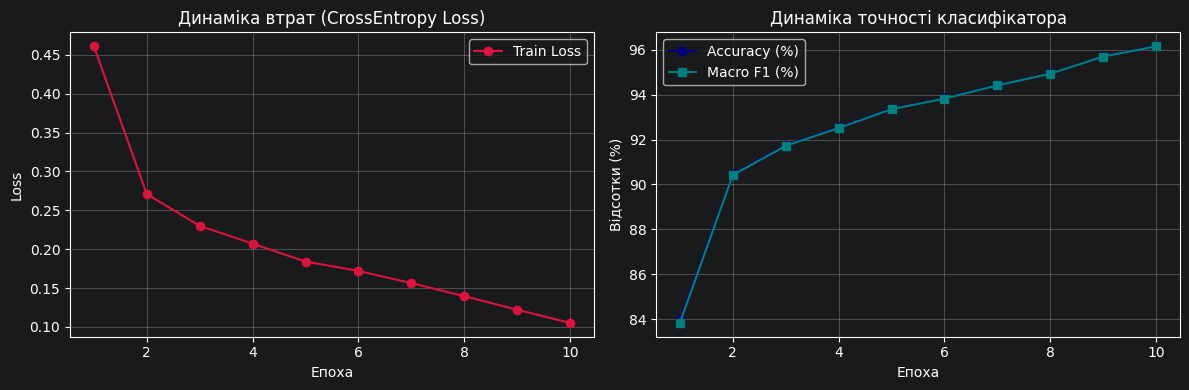


--------------------------------------------------
 РЕЗУЛЬТАТИ ПРЯМОЇ КЛАСИФІКАЦІЇ (ТЕСТОВИЙ НАБІР)
--------------------------------------------------
              precision    recall  f1-score   support

 T-shirt/top     0.8825    0.8790    0.8808      1000
     Trouser     0.9980    0.9800    0.9889      1000
    Pullover     0.9307    0.9000    0.9151      1000
       Dress     0.8883    0.9700    0.9273      1000
        Coat     0.8914    0.9190    0.9050      1000
      Sandal     0.9900    0.9880    0.9890      1000
       Shirt     0.8341    0.7740    0.8029      1000
     Sneaker     0.9495    0.9770    0.9630      1000
         Bag     0.9831    0.9860    0.9845      1000
  Ankle boot     0.9784    0.9530    0.9656      1000

    accuracy                         0.9326     10000
   macro avg     0.9326    0.9326    0.9322     10000
weighted avg     0.9326    0.9326    0.9322     10000



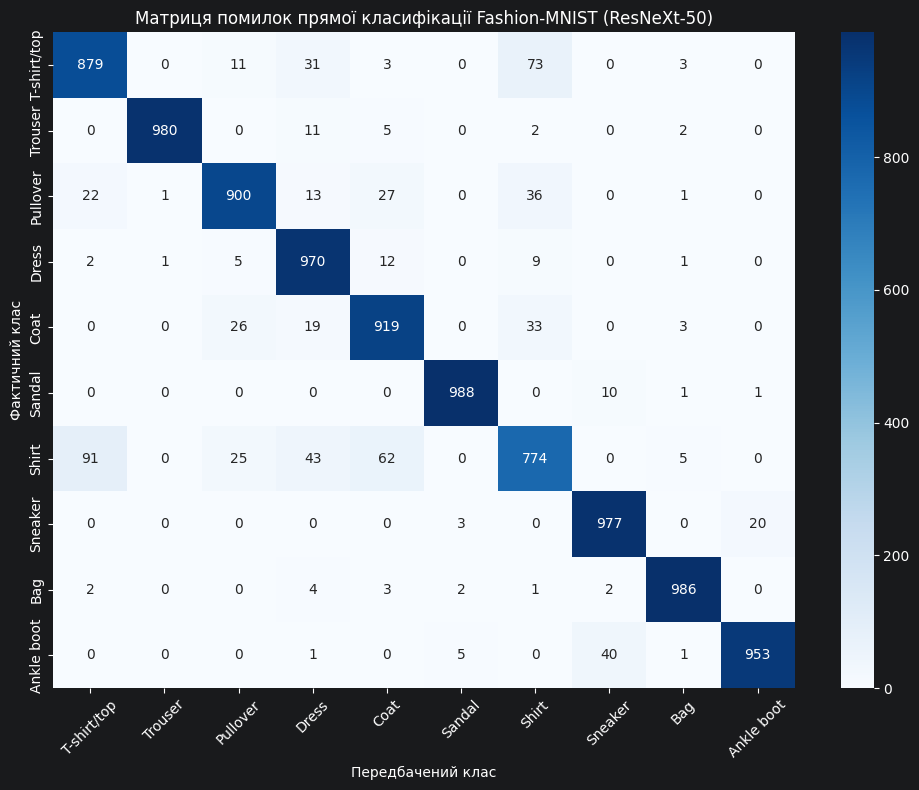

In [35]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs_cls + 1), cls_history['loss'], marker='o', color='crimson', label='Train Loss')
plt.title('Динаміка втрат (CrossEntropy Loss)')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs_cls + 1), cls_history['acc'], marker='o', color='navy', label='Accuracy (%)')
plt.plot(range(1, epochs_cls + 1), cls_history['f1'], marker='s', color='teal', label='Macro F1 (%)')
plt.title('Динаміка точності класифікатора')
plt.xlabel('Епоха')
plt.ylabel('Відсотки (%)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig('direct_classification_learning_curves.png')
plt.show()

cls_model.eval()
all_preds_cls = []
all_targets_cls = []

with torch.no_grad():
    for imgs, labels in test_loader_cls:
        imgs = imgs.to(device)
        outputs = cls_model(imgs)
        _, predicted = outputs.max(1)
        all_preds_cls.extend(predicted.cpu().numpy())
        all_targets_cls.extend(labels.numpy())

print("\n" + "-" * 50)
print(" РЕЗУЛЬТАТИ ПРЯМОЇ КЛАСИФІКАЦІЇ (ТЕСТОВИЙ НАБІР)")
print("-" * 50)
print(classification_report(all_targets_cls, all_preds_cls, target_names=categories, digits=4))

cm_cls = confusion_matrix(all_targets_cls, all_preds_cls)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_cls, annot=True, fmt='d', cmap='Blues',
            xticklabels=categories, yticklabels=categories)
plt.title('Матриця помилок прямої класифікації Fashion-MNIST (ResNeXt-50)')
plt.xlabel('Передбачений клас')
plt.ylabel('Фактичний клас')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('direct_classification_confusion_matrix.png')
plt.show()


In [36]:
print("\n" + "=" * 80)
print("ЧАСТИНА 2: НАВЧАННЯ СІАМСЬКОЇ МЕРЕЖІ ТА t-SNE АНАЛІЗ")
print("=" * 80)

feature_extractor = get_feature_extractor(model_type=MODEL_MODE, feature_dim=FEATURE_DIM)
siamese_model = SiameseNet(feature_extractor, feature_dim=FEATURE_DIM).to(device)

siamese_dataset = SiameseFashionMNIST(train_mnist)
train_loader_siam = DataLoader(siamese_dataset, batch_size=64, shuffle=True)
test_raw_loader = DataLoader(test_mnist, batch_size=256, shuffle=False)

criterion_siam = nn.BCELoss()
optimizer_siam = optim.Adam(siamese_model.parameters(), lr=1e-3)

siam_history = {'loss': [], 'mae': [], 'acc': [], 'f1': []}

epochs_siam = 10
for epoch in range(epochs_siam):
    start_time = time.time()
    siamese_model.train()
    running_loss = 0.0
    running_mae = 0.0
    all_siam_targets = []
    all_siam_preds_binary = []

    for img_a, img_b, target in train_loader_siam:
        img_a, img_b, target = img_a.to(device), img_b.to(device), target.to(device)

        optimizer_siam.zero_grad()
        outputs = siamese_model(img_a, img_b)
        loss = criterion_siam(outputs, target)
        loss.backward()
        optimizer_siam.step()

        running_loss += loss.item() * img_a.size(0)
        running_mae += torch.sum(torch.abs(outputs - target)).item()

        preds_binary = (outputs >= 0.5).float()
        all_siam_preds_binary.extend(preds_binary.cpu().numpy().squeeze())
        all_siam_targets.extend(target.cpu().numpy().squeeze())

    epoch_time = time.time() - start_time
    epoch_loss = running_loss / len(siamese_dataset)
    epoch_mae = running_mae / len(siamese_dataset)
    epoch_acc = accuracy_score(all_siam_targets, all_siam_preds_binary)
    p_siam, r_siam, f1_siam, _ = precision_recall_fscore_support(
        all_siam_targets, all_siam_preds_binary, average='binary', zero_division=0
    )

    siam_history['loss'].append(epoch_loss)
    siam_history['mae'].append(epoch_mae)
    siam_history['acc'].append(epoch_acc * 100)
    siam_history['f1'].append(f1_siam * 100)

    print(f"Epoch [{epoch+1}/{epochs_siam}] "
          f"| Loss: {epoch_loss:.4f} "
          f"| MAE: {epoch_mae:.4f} "
          f"| Accuracy: {epoch_acc:.4f} "
          f"| Precision: {p_siam:.4f} "
          f"| Recall: {r_siam:.4f} "
          f"| F1-Score: {f1_siam:.4f}"
          f"| Time: {epoch_time:.2f}s ")

print("\n--- Навчання Сіамської мережі завершено! ---")


ЧАСТИНА 2: НАВЧАННЯ СІАМСЬКОЇ МЕРЕЖІ ТА t-SNE АНАЛІЗ
Ініціалізація ВЛАСНОЇ архітектури ResNeXt-50...


/tmp/ipykernel_1093/3904341103.py:4: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  self.labels = np.array(mnist_dataset.targets)


Epoch [1/10] | Loss: 0.4864 | MAE: 0.3489 | Accuracy: 0.7706 | Precision: 0.7446 | Recall: 0.8228 | F1-Score: 0.7818| Time: 498.80s 
Epoch [2/10] | Loss: 0.3252 | MAE: 0.2113 | Accuracy: 0.8636 | Precision: 0.8189 | Recall: 0.9332 | F1-Score: 0.8723| Time: 498.81s 
Epoch [3/10] | Loss: 0.2826 | MAE: 0.1793 | Accuracy: 0.8797 | Precision: 0.8450 | Recall: 0.9296 | F1-Score: 0.8853| Time: 498.53s 
Epoch [4/10] | Loss: 0.2339 | MAE: 0.1470 | Accuracy: 0.9021 | Precision: 0.8770 | Recall: 0.9350 | F1-Score: 0.9051| Time: 498.53s 
Epoch [5/10] | Loss: 0.2094 | MAE: 0.1295 | Accuracy: 0.9127 | Precision: 0.8874 | Recall: 0.9452 | F1-Score: 0.9154| Time: 498.41s 
Epoch [6/10] | Loss: 0.1949 | MAE: 0.1185 | Accuracy: 0.9203 | Precision: 0.8968 | Recall: 0.9496 | F1-Score: 0.9225| Time: 498.50s 
Epoch [7/10] | Loss: 0.1761 | MAE: 0.1082 | Accuracy: 0.9270 | Precision: 0.9083 | Recall: 0.9497 | F1-Score: 0.9286| Time: 497.99s 
Epoch [8/10] | Loss: 0.1612 | MAE: 0.0970 | Accuracy: 0.9337 | Precis

In [38]:
checkpoint_siamese = {
    'epoch': epochs_cls,
    'model_state_dict': siamese_model.state_dict(),
    'optimizer_state_dict': optimizer_siam.state_dict(),
    'history': siam_history,
}
torch.save(checkpoint_siamese, 'resnext50_siam_checkpoint.pt')
torch.save(siamese_model.state_dict(), 'resnext50_siamese.pth')

In [43]:
feature_extractor = get_feature_extractor(model_type=MODEL_MODE, feature_dim=FEATURE_DIM)
siamese_model = SiameseNet(feature_extractor, feature_dim=FEATURE_DIM).to(device)
siamese_checkpoint = torch.load('resnext50_siam_checkpoint.pt', map_location=device)

siamese_model.load_state_dict(siamese_checkpoint['model_state_dict'])
history = checkpoint['history']

Ініціалізація ВЛАСНОЇ архітектури ResNeXt-50...


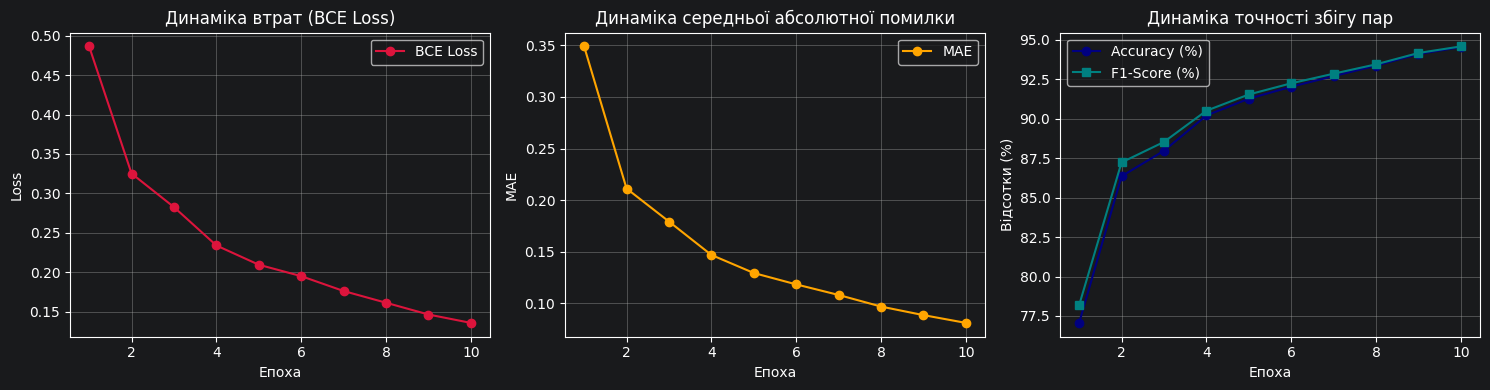

In [51]:
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.plot(range(1, epochs_siam + 1), siam_history['loss'], marker='o', color='crimson', label='BCE Loss')
plt.title('Динаміка втрат (BCE Loss)')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(range(1, epochs_siam + 1), siam_history['mae'], marker='o', color='orange', label='MAE')
plt.title('Динаміка середньої абсолютної помилки')
plt.xlabel('Епоха')
plt.ylabel('MAE')
plt.grid(True)
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(range(1, epochs_siam + 1), siam_history['acc'], marker='o', color='navy', label='Accuracy (%)')
plt.plot(range(1, epochs_siam + 1), siam_history['f1'], marker='s', color='teal', label='F1-Score (%)')
plt.title('Динаміка точності збігу пар')
plt.xlabel('Епоха')
plt.ylabel('Відсотки (%)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig('siamese_learning_curves.png')
plt.show()

/tmp/ipykernel_1093/3904341103.py:4: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  self.labels = np.array(mnist_dataset.targets)



ТОЧНІ ФІНАЛЬНІ ПОКАЗНИКИ ЯКОСТІ МЕРЕЖІ
ROC-AUC Score: 0.9869

Детальний звіт класифікації (Classification Report):
                 precision    recall  f1-score   support

Різні класи (0)     0.9527    0.9304    0.9415      5003
  Один клас (1)     0.9320    0.9538    0.9427      4997

       accuracy                         0.9421     10000
      macro avg     0.9423    0.9421    0.9421     10000
   weighted avg     0.9423    0.9421    0.9421     10000



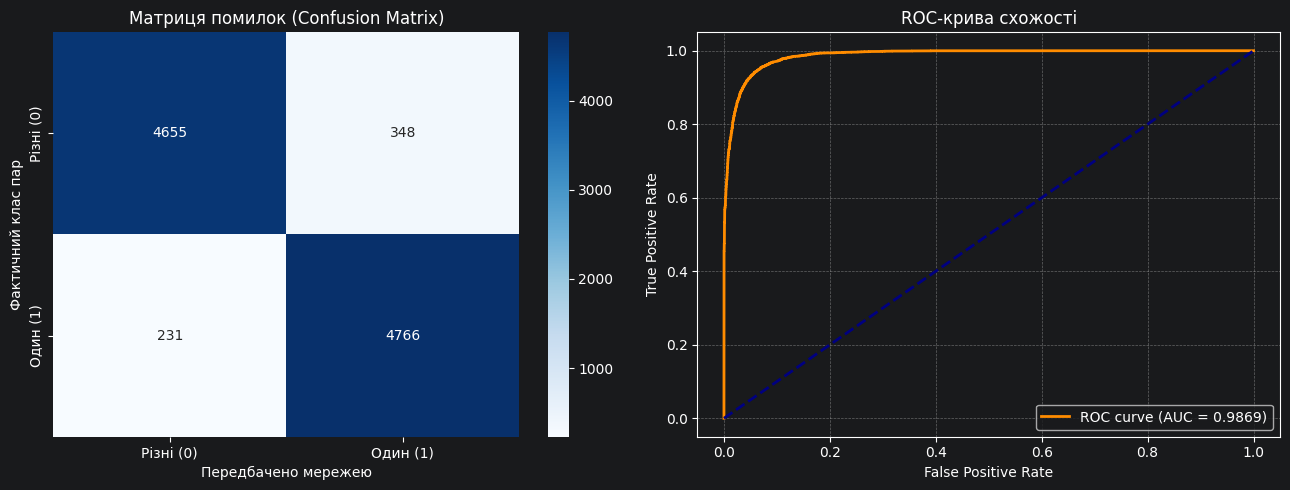

In [52]:
evaluate_siamese_metrics(siamese_model, test_mnist, device)


Візуалізація передбачень схожості пар зображень...


/tmp/ipykernel_1093/3904341103.py:4: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  self.labels = np.array(mnist_dataset.targets)


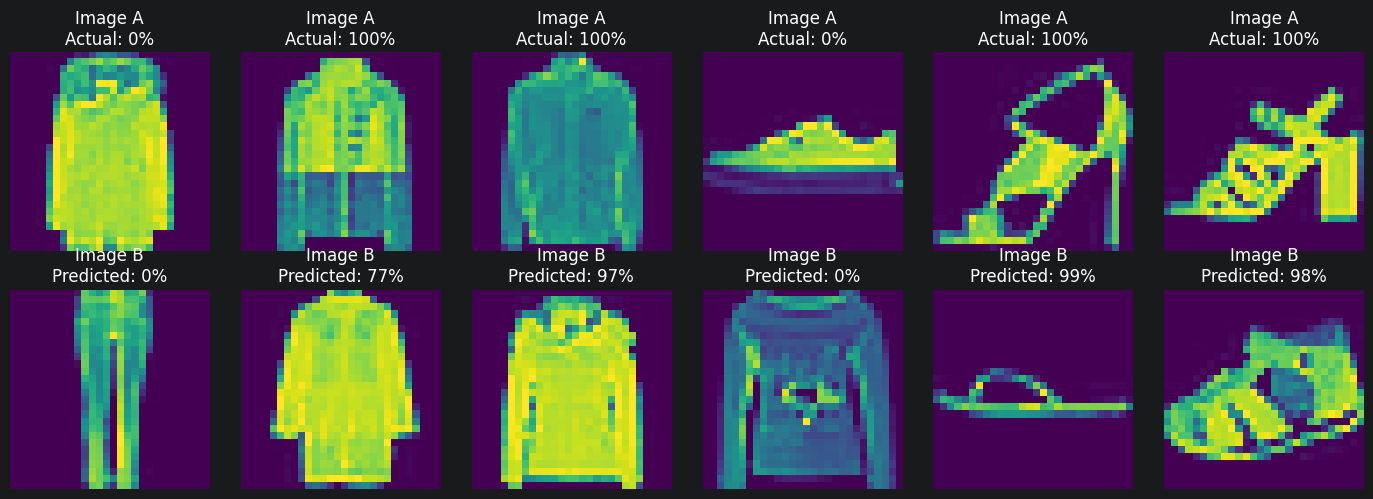

In [53]:
print("\nВізуалізація передбачень схожості пар зображень...", flush=True)
show_model_predictions(siamese_model, test_mnist, device, examples_amount=6)


Генерація t-SNE графіка для векторів ознак...
Обчислення t-SNE проекції на 2D площину...
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 10000 samples in 0.001s...


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


[t-SNE] Computed neighbors for 10000 samples in 0.891s...
[t-SNE] Computed conditional probabilities for sample 1000 / 10000
[t-SNE] Computed conditional probabilities for sample 2000 / 10000
[t-SNE] Computed conditional probabilities for sample 3000 / 10000
[t-SNE] Computed conditional probabilities for sample 4000 / 10000
[t-SNE] Computed conditional probabilities for sample 5000 / 10000
[t-SNE] Computed conditional probabilities for sample 6000 / 10000
[t-SNE] Computed conditional probabilities for sample 7000 / 10000
[t-SNE] Computed conditional probabilities for sample 8000 / 10000
[t-SNE] Computed conditional probabilities for sample 9000 / 10000
[t-SNE] Computed conditional probabilities for sample 10000 / 10000
[t-SNE] Mean sigma: 0.125130
[t-SNE] KL divergence after 250 iterations with early exaggeration: 69.082825
[t-SNE] KL divergence after 500 iterations: 1.320416


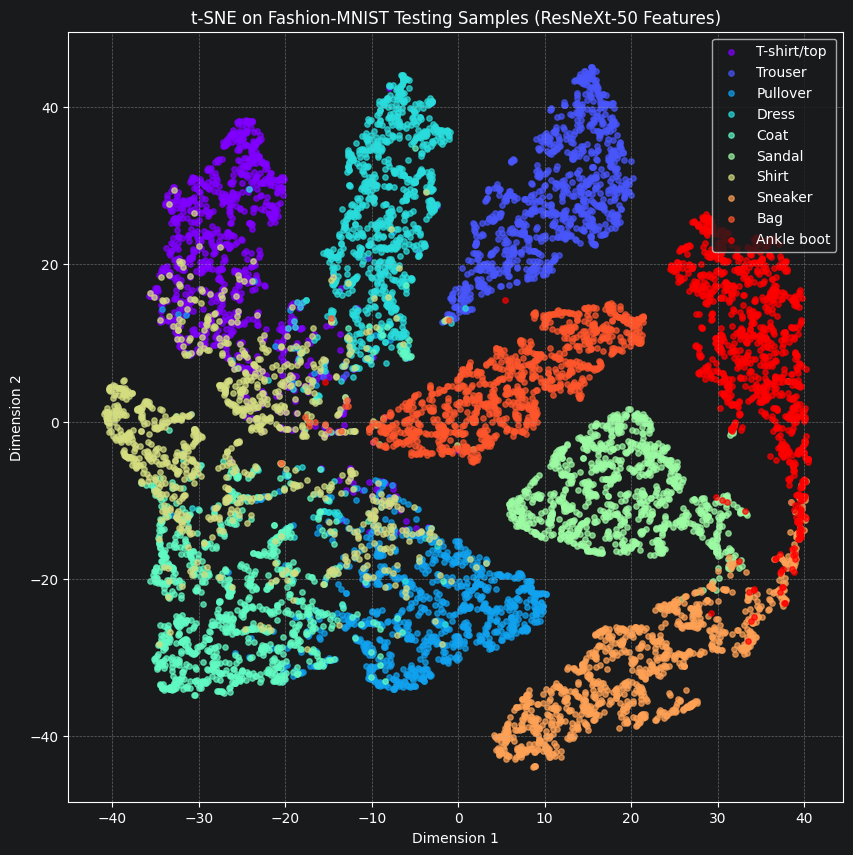

In [54]:
print("\nГенерація t-SNE графіка для векторів ознак...", flush=True)
visualize_tsne(feature_extractor, test_raw_loader, device)

In [59]:
siamese_test_ds = SiameseFashionMNIST(test_mnist)
targets, match_probs, binary_matches = evaluate_classifier_for_matching(
    classifier_model=cls_model,
    siamese_test_ds=siamese_test_ds,
    device=device
)

/tmp/ipykernel_1093/3904341103.py:4: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  self.labels = np.array(mnist_dataset.targets)


In [61]:
def print_and_plot_matching_metrics(all_targets, all_preds_prob, threshold=0.5):
    all_preds_binary = (all_preds_prob >= threshold).astype(int)

    auc_score = roc_auc_score(all_targets, all_preds_prob)
    cm = confusion_matrix(all_targets, all_preds_binary)

    print("\n" + "="*50, flush=True)
    print("ПОКАЗНИКИ ЯКОСТІ ПОРІВНЯННЯ ПАР ЧЕРЕЗ КЛАСИФІКАТОР", flush=True)
    print("="*50, flush=True)
    print(f"ROC-AUC Score: {auc_score:.4f}\n", flush=True)
    print("Детальний звіт класифікації (Classification Report):", flush=True)
    print(classification_report(all_targets, all_preds_binary,
                                target_names=['Різні класи (0)', 'Один клас (1)'],
                                digits=4), flush=True)

    fig, axs = plt.subplots(1, 2, figsize=(13, 5))

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axs[0],
                xticklabels=['Різні (0)', 'Один (1)'],
                yticklabels=['Різні (0)', 'Один (1)'])
    axs[0].set_title('Матриця помилок (Confusion Matrix) — Класифікатор')
    axs[0].set_xlabel('Передбачено мережею')
    axs[0].set_ylabel('Фактичний клас пар')

    fpr, tpr, _ = roc_curve(all_targets, all_preds_prob)
    axs[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.4f})')
    axs[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    axs[1].set_title('ROC-крива схожості пар (Класифікатор)')
    axs[1].set_xlabel('False Positive Rate')
    axs[1].set_ylabel('True Positive Rate')
    axs[1].legend(loc="lower right")
    axs[1].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig('classifier_matching_confusion_matrix_and_roc.png')
    plt.show()


ПОКАЗНИКИ ЯКОСТІ ПОРІВНЯННЯ ПАР ЧЕРЕЗ КЛАСИФІКАТОР
ROC-AUC Score: 0.9931

Детальний звіт класифікації (Classification Report):
                 precision    recall  f1-score   support

Різні класи (0)     0.8769    0.9882    0.9292      5003
  Один клас (1)     0.9865    0.8611    0.9195      4997

       accuracy                         0.9247     10000
      macro avg     0.9317    0.9247    0.9244     10000
   weighted avg     0.9317    0.9247    0.9244     10000



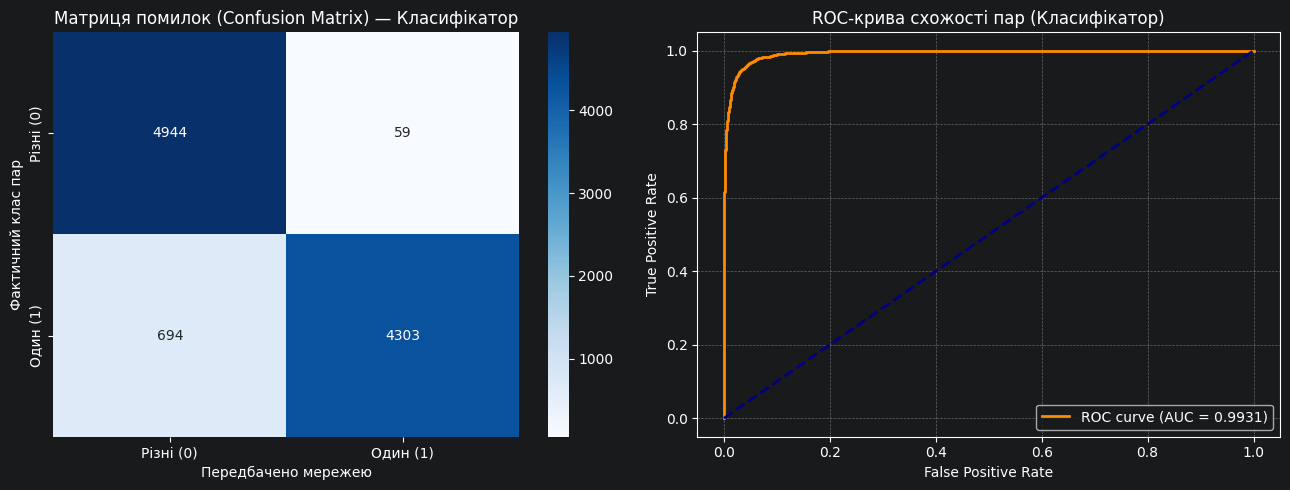

In [62]:
print_and_plot_matching_metrics(targets, match_probs)